# 01 · FI-2010: qualità, distribuzioni e confini

FI-2010 (Ntakaris et al., 2018) contiene dieci giorni di book L2 a 10 livelli per cinque titoli del Nasdaq Nordic, con prezzi normalizzati (*DecPre*) e un'osservazione ogni 10 eventi. Ogni file giornaliero concatena i cinque titoli senza identificativo: i confini sono individuati dove il midpoint salta di oltre il 5% e ogni titolo-giorno diventa una sessione separata.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
from market_making_tesi import storage
from market_making_tesi.parsers import load_fi2010_matrix, fi2010_stock_segments
quality = R.load(ROOT, "quality").query("dataset == 'fi2010'")
counts = quality.pivot(index="session", columns="symbol", values="records")
display(counts)
anomalies = quality[["ts_decreasing", "crossed", "nonpositive_size", "nonfinite_mid"]].sum()
display(anomalies.to_frame("anomalie"))
assert anomalies.sum() == 0
print(f"{it(counts.values.sum())} snapshot in {counts.size} sessioni titolo-giorno")

symbol,stock1,stock2,stock3,stock4,stock5
session,,,,,
day01,3454,6318,4922,10719,14099
day02,5079,6122,5965,6712,14519
day03,3903,5411,4027,5186,10008
day04,2806,6992,5342,10819,11064
day05,3030,6728,5946,6378,12703
day06,2263,6243,5607,7007,18032
day07,2801,7060,6740,7854,12891
day08,2647,8662,8591,13229,22349
day09,1873,9271,10036,12880,18112


,anomalie
ts_decreasing,0.0
crossed,0.0
nonpositive_size,0.0
nonfinite_mid,0.0


394.337 snapshot in 50 sessioni titolo-giorno


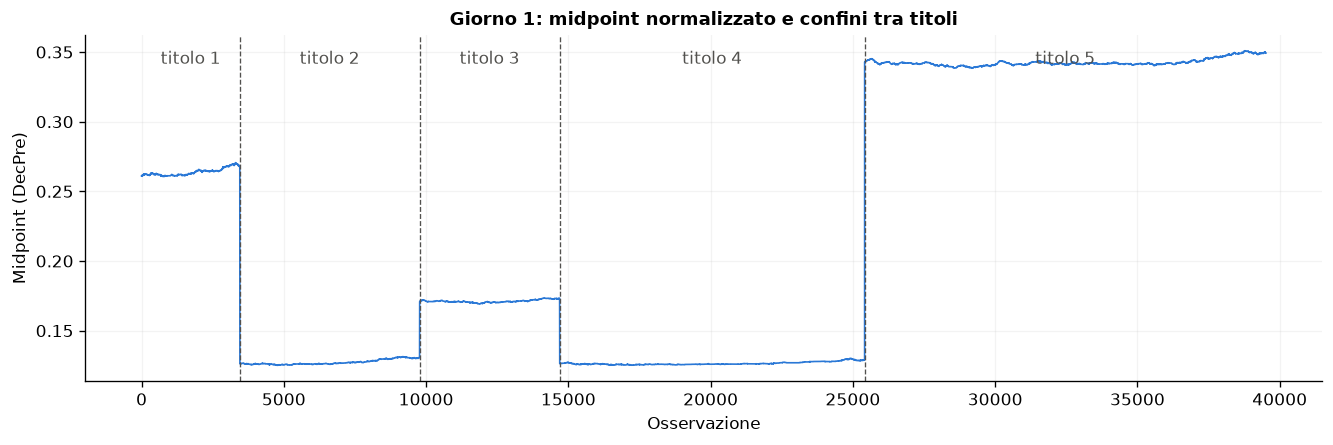

In [2]:
matrix = load_fi2010_matrix(ROOT / "data/raw/fi2010/fi2010_day01.txt")
mid = (matrix[0] + matrix[2]) / 2
bounds = fi2010_stock_segments(matrix)
fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
ax.plot(mid, color=R.COLORS["touch"], linewidth=1)
for start, _ in bounds[1:]:
    ax.axvline(start, color=R.INK, linewidth=0.8, linestyle="--")
for k, (start, stop) in enumerate(bounds, 1):
    ax.text((start + stop) / 2, mid.max(), f"titolo {k}", ha="center", va="top", color=R.INK)
ax.set(title="Giorno 1: midpoint normalizzato e confini tra titoli", xlabel="Osservazione", ylabel="Midpoint (DecPre)")
fig.savefig(FIGURES / "fi2010_confini.png", dpi=180, bbox_inches="tight")
plt.show()

,spread_mediano,spread_p95,quota_mid_invariato,dev_std_variazioni,profondita_mediana
symbol,,,,,
stock1,0.0006,0.0011,0.588925,0.000083,0.00668
stock2,0.0002,0.0004,0.775359,0.000034,0.02930
stock3,0.0002,0.0004,0.762457,0.000036,0.03331
stock4,0.0002,0.0004,0.841083,0.000029,0.02994
stock5,0.0005,0.0010,0.784846,0.000054,0.00700


,1,2,3,4,5,>=6
symbol,,,,,,
stock1,3.3%,6.6%,10.8%,13.3%,13.8%,52.3%
stock2,35.0%,35.1%,20.5%,7.6%,1.4%,0.3%
stock3,31.9%,35.6%,24.0%,7.3%,1.0%,0.2%
stock4,26.5%,32.6%,27.7%,11.1%,1.8%,0.2%
stock5,3.9%,5.8%,8.7%,14.7%,17.3%,49.6%


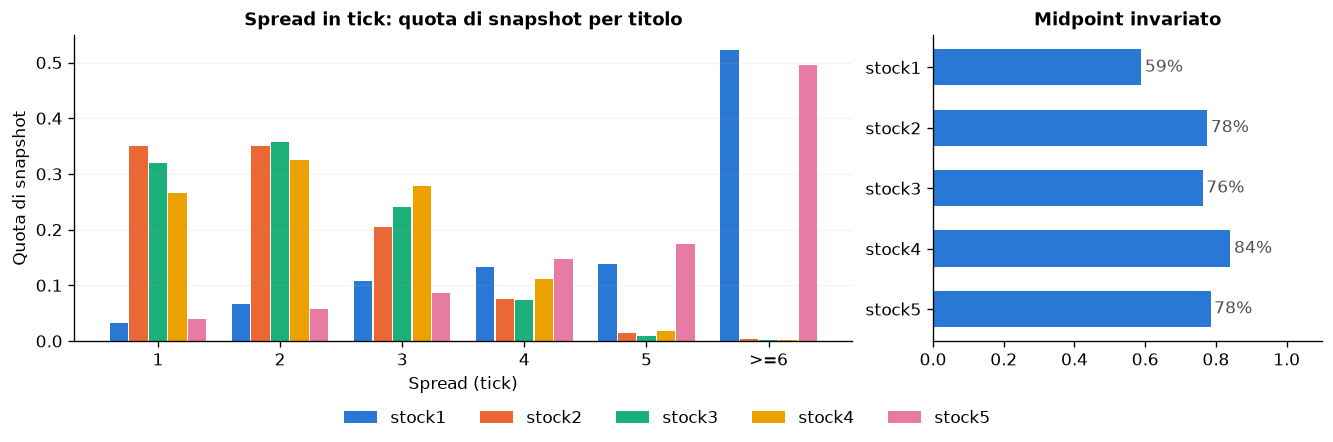

Il midpoint resta invariato tra due snapshot consecutivi nel 77,7% dei casi. È il motivo per cui `touch` esegue molte quote: con il mercato fermo il best bid resta uguale alla quota.

In [3]:
rows = []
for session, symbol, path in storage.sessions(ROOT / "data/interim", "fi2010", "snapshots"):
    t = pd.read_parquet(path, columns=["bid_px_1", "ask_px_1", "bid_sz_1", "ask_sz_1"])
    m = (t.bid_px_1 + t.ask_px_1) / 2
    rows.append(pd.DataFrame({"session": session, "symbol": symbol, "spread": t.ask_px_1 - t.bid_px_1,
                              "ret": m.diff(), "depth": t.bid_sz_1 + t.ask_sz_1}))
eda = pd.concat(rows)
desc = eda.groupby("symbol").agg(spread_mediano=("spread", "median"), spread_p95=("spread", lambda x: x.quantile(.95)),
                                 quota_mid_invariato=("ret", lambda x: (x == 0).mean()),
                                 dev_std_variazioni=("ret", "std"), profondita_mediana=("depth", "median"))
display(desc)
TICK = 0.0001  # passo minimo dei prezzi DecPre
eda["ticks"] = (eda.spread / TICK).round().clip(upper=6).astype(int)
shares = eda.groupby("symbol").ticks.value_counts(normalize=True).unstack(fill_value=0)
shares.columns = [f"{c}" if c < 6 else ">=6" for c in shares.columns]
display(shares.style.format("{:.1%}"))
STOCK_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # slot 1-5 validati
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained", gridspec_kw={"width_ratios": [2, 1]})
x = np.arange(len(shares.columns))
for i, (symbol, row) in enumerate(shares.iterrows()):
    axes[0].bar(x + (i - 2) * 0.16, row.values, 0.15, color=STOCK_COLORS[i], label=symbol)
axes[0].set_xticks(x, shares.columns)
axes[0].set(title="Spread in tick: quota di snapshot per titolo", xlabel="Spread (tick)", ylabel="Quota di snapshot")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=5, frameon=False)
still = eda.groupby("symbol").ret.apply(lambda r: (r.dropna() == 0).mean())
axes[1].barh(still.index[::-1], still.values[::-1], color=R.COLORS["touch"], height=0.6)
for y, v in enumerate(still.values[::-1]):
    axes[1].text(v + 0.01, y, pct(v, 0), va="center", color=R.INK)
axes[1].set(title="Midpoint invariato", xlim=(0, 1.1))
axes[1].grid(False)
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "fi2010_distribuzioni.png", dpi=180, bbox_inches="tight")
plt.show()
display(Markdown(f"Il midpoint resta invariato tra due snapshot consecutivi nel {pct((eda.ret == 0).mean())} dei casi. "
                 "È il motivo per cui `touch` esegue molte quote: con il mercato fermo il best bid resta uguale alla quota."))

## Volatilità, finestra di stima e regime di bassa volatilità

La strategia opera solo quando la volatilità è bassa. La stima a ogni osservazione è la deviazione standard delle variazioni del midpoint nelle ultime *W* osservazioni: una finestra corta reagisce subito agli shock ma è rumorosa, una lunga è stabile ma lenta. La soglia è un quantile della volatilità osservata il **giorno 1** (calibrazione) per lo stesso titolo; le combinazioni provate in validazione (giorni 2-3) sono *W* ∈ {20, 100} e quantile ∈ {50%, 75%, 90%}.

**Soglie di volatilità stimate sul giorno 1, per titolo**

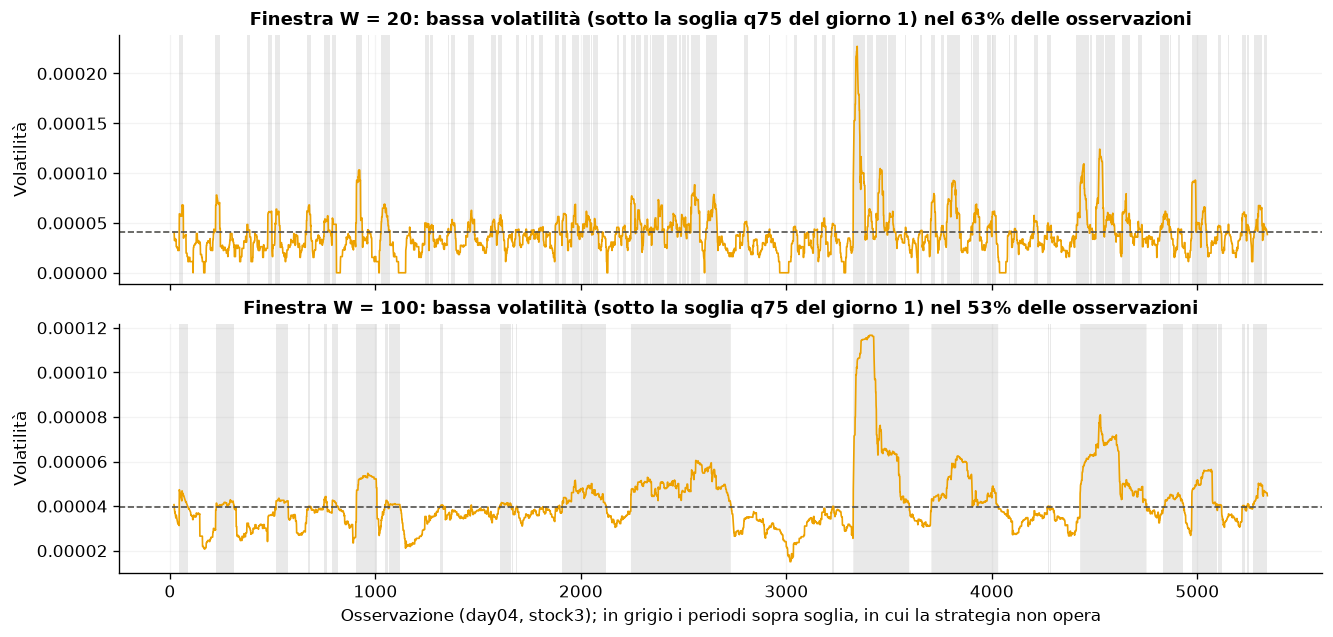

In [4]:
cal = R.load(ROOT, "calibration").query("dataset == 'fi2010' and session == 'day01'").set_index("symbol")
cols = [f"threshold_w{w}_q{q}" for w in (20, 100) for q in (50, 75, 90)]
table = cal[cols].T
table.index = pd.MultiIndex.from_tuples([(f"W = {c.split('_')[1][1:]}", f"q{c.split('_')[2][1:]}") for c in cols],
                                        names=["finestra", "quantile"])
display(Markdown("**Soglie di volatilità stimate sul giorno 1, per titolo**"))
display(table.style.format("{:.2e}"))

session, symbol = "day04", "stock3"
path = next(p for s_, sym, p in storage.sessions(ROOT / "data/interim", "fi2010", "snapshots") if s_ == session and sym == symbol)
t = pd.read_parquet(path, columns=["bid_px_1", "ask_px_1"])
ret = ((t.bid_px_1 + t.ask_px_1) / 2).diff()
row = cal.loc[symbol]
fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, layout="constrained")
for ax, w in zip(axes, (20, 100)):
    vol = ret.rolling(w, min_periods=min(20, w)).std()
    thr = row[f"threshold_w{w}_q75"]
    ax.plot(vol.index, vol, color=R.COLORS["queue"], linewidth=1)
    ax.axhline(thr, color=R.INK, linestyle="--", linewidth=1)
    ax.fill_between(vol.index, 0, 1, where=(vol > thr).to_numpy(), transform=ax.get_xaxis_transform(),
                    color=R.INK, alpha=0.12, linewidth=0, step="post")
    share = (vol.dropna() <= thr).mean()
    ax.set(ylabel="Volatilità", title=f"Finestra W = {w}: bassa volatilità (sotto la soglia q75 del giorno 1) nel {pct(share, 0)} delle osservazioni")
axes[1].set(xlabel=f"Osservazione ({session}, {symbol}); in grigio i periodi sopra soglia, in cui la strategia non opera")
fig.savefig(FIGURES / "fi2010_volatilita_finestre.png", dpi=180, bbox_inches="tight")
plt.show()